# Module 9 — Audit metrics, code, and claims
## Worked examples for review

Use `module09_in_class.ipynb` to make predictions first. This notebook contains complete answers and runnable checks. Select this repo's `.venv` kernel after `uv sync --frozen`, then run from top to bottom. All data are invented teaching examples; no downloads or API keys are needed.

Define → predict → inspect → verify → record. Passing small checks supports a claim; it is not proof for every input.


In [1]:
import pandas as pd

print("Ready for the four examples.")


Ready for the four examples.


## 1 · Highest-spending customers
**Request:** Find the three customers who spent the most across the supplied orders.

This is the customer example from the programming-time slides. Each order counts once. A customer without an email still counts. Customer IDs identify people; the repeated customer row represents another contact email, not another person.

For this exercise, every order has a recorded amount and a matching customer. Names are unique across customer IDs, and repeated rows for an ID agree on the name. Return a Series indexed by name, largest total first. Assume no tied totals and a positive integer `n`; if fewer than `n` customers ordered, return them all.


In [2]:
orders = pd.DataFrame({
    "order_id": [1, 2, 3, 4, 5, 6],
    "customer_id": [1, 2, 2, 3, 4, 5],
    "amount": [120, 80, 90, 300, 40, 210]
})
customers = pd.DataFrame({
    "customer_id": [1, 2, 3, 4, 5, 1],
    "name": ["Ana", "Ben", "Cleo", "Dev", "Eli", "Ana"],
    "email": ["a@x.com", "b@x.com", None, "d@x.com", "e@x.com", "ana@y.com"]
})
print("Orders:\n", orders.to_string(index=False))
print("\nCustomers:\n", customers.to_string(index=False))


Orders:
  order_id  customer_id  amount
        1            1     120
        2            2      80
        3            2      90
        4            3     300
        5            4      40
        6            5     210

Customers:
  customer_id name     email
           1  Ana   a@x.com
           2  Ben   b@x.com
           3 Cleo      None
           4  Dev   d@x.com
           5  Eli   e@x.com
           1  Ana ana@y.com


### Predict
Add the orders by hand. Record all five customer totals and the top three in order before running the function.

**My totals and ranking:**


In [3]:
def top_customers(orders, customers, n=3):
    df = orders.merge(customers, on="customer_id")
    df = df.dropna()
    totals = df.groupby("name")["amount"].sum()
    return totals.sort_values()[:n]

print(top_customers(orders, customers))


name
Dev     40
Ben    170
Eli    210
Name: amount, dtype: int64


### Worked diagnosis
The faulty output is Dev 40, Ben 170, Eli 210.

| Operation | Problem | Evidence |
| --- | --- | --- |
| `merge(customers, ...)` | A repeated contact row duplicates an order. | Ana's 120 appears twice; 6 orders become 7 rows. |
| `dropna()` | Missing email removes a valid customer order. | Cleo's 300 disappears; 7 merged rows become 6. |
| `sort_values()` | Ascending order selects the lowest totals. | It returns Dev, Ben, Eli. |

Before sorting, the faulty totals are Ana 240, Ben 170, Dev 40, and Eli 210. Correct totals are Cleo 300, Eli 210, Ben 170, Ana 120, and Dev 40.

The exercise states that repeated IDs agree on the name, so one ID/name row per customer is sufficient for this report. Contact emails are irrelevant to spending. If an ID had conflicting names, resolve that inconsistency rather than silently choosing one. In general, different people can share a name; grouping by name is safe here only because the exercise explicitly rules that out.


In [4]:
def top_customers_fixed(orders, customers, n=3):
    names = customers[["customer_id", "name"]].drop_duplicates("customer_id")
    df = orders.merge(names, on="customer_id", validate="many_to_one")
    totals = df.groupby("name")["amount"].sum()
    return totals.sort_values(ascending=False).head(n)

print(top_customers_fixed(orders, customers))


name
Cleo    300
Eli     210
Ben     170
Name: amount, dtype: int64


### Verify and test
1. Compare your corrected top three with your hand calculation.
2. Request all five customers. Does each total match? Why might checking only the top three miss a remaining error?
3. Add another contact row for Ana without adding an order. Predict and check whether any total changes.
4. Give Cleo an email. Predict and check whether the ranking changes.
5. Request ten customers. How many should be returned?

Use new copies for the changed tables. Record expected and actual results, then explain what the checks establish.

**Results and explanation:**


In [5]:
expected = pd.Series(
    [300, 210, 170, 120, 40],
    index=pd.Index(["Cleo", "Eli", "Ben", "Ana", "Dev"], name="name"),
    name="amount"
)
pd.testing.assert_series_equal(top_customers_fixed(orders, customers), expected.head(3))
pd.testing.assert_series_equal(top_customers_fixed(orders, customers, n=5), expected)

extra_contact = pd.concat([
    customers,
    pd.DataFrame({"customer_id": [1], "name": ["Ana"], "email": ["ana@z.com"]})
], ignore_index=True)
pd.testing.assert_series_equal(top_customers_fixed(orders, extra_contact, n=5), expected)

with_email = customers.copy()
with_email.loc[with_email["customer_id"] == 3, "email"] = "cleo@x.com"
pd.testing.assert_series_equal(top_customers_fixed(orders, with_email, n=5), expected)
pd.testing.assert_series_equal(top_customers_fixed(orders, customers, n=10), expected)
print("All checks passed.")


All checks passed.


### What the checks establish
The corrected report preserves each order's contribution, includes customers without email, and ranks spending in descending order. Extra contact rows and email changes leave the answer unchanged. Asking for ten returns the five customers with orders.

Checking all five totals matters: Ana's duplicated total of 240 is visible after the other fixes, but different data could hide a duplicated lower-ranked customer outside the top three. These checks do not establish rules for conflicting names, unmatched IDs, missing amounts, or ties; those need requirements before extending the function.


## 2 · Average tip per visit
**Requirement:** report average tip per visit. A blank tip explicitly means the customer left no tip. Each visit has at least one service.

**Pause and predict:** Visit A has a \$10 tip and two services; visit B has no tip and one service. What is the mean tip per visit? What happens if we calculate the mean after the merge?

In [6]:
visits = pd.DataFrame({"visit": ["A", "B"], "tip": [10.0, None]})
services = pd.DataFrame({"visit": ["A", "A", "B"],
                         "service": ["haircut", "coloring", "haircut"]})
print("Visits:\n", visits.to_string(index=False))
print("\nServices:\n", services.to_string(index=False))

Visits:
 visit  tip
    A 10.0
    B  NaN

Services:
 visit  service
    A  haircut
    A coloring
    B  haircut


In [7]:
clean_visits = visits.copy()
clean_visits["tip"] = clean_visits["tip"].fillna(0)
merged = services.merge(clean_visits, on="visit", validate="many_to_one")
print(merged.to_string(index=False))
wrong_mean_tip = merged["tip"].mean()
print("Mean after merge:", round(wrong_mean_tip, 2))

visit  service  tip
    A  haircut 10.0
    A coloring 10.0
    B  haircut  0.0
Mean after merge: 6.67


### Worked solution
The expected result is **\$5 = (\$10 + \$0) / 2 visits**. The merged table has one row per service. It averages `[10, 10, 0]`, producing about **\$6.67**. The merge validation passes because the join relationship is valid; it does not guarantee that a later aggregation uses the right unit.

In [8]:
mean_tip = clean_visits["tip"].mean()
print("Mean per visit:", mean_tip)
assert mean_tip == 5.0

# A separate hand calculation from the two visits.
assert mean_tip == (10 + 0) / 2

Mean per visit: 5.0


### New check and assumption check
Add a third service to visit A without changing its tip. The mean tip per visit must remain \$5. Then consider a different data dictionary: a blank means **not recorded**. Would filling with zero still be justified?

In [9]:
more_services = pd.concat([
    services, pd.DataFrame({"visit": ["A"], "service": ["styling"]})
], ignore_index=True)
more_merged = more_services.merge(clean_visits, on="visit", validate="many_to_one")
print("Incorrect mean with another service:", more_merged["tip"].mean())
print("Correct visit mean is unchanged:", clean_visits["tip"].mean())
assert clean_visits["tip"].mean() == 5.0

Incorrect mean with another service: 7.5
Correct visit mean is unchanged: 5.0


**If blank means unknown:** the all-visit mean is not identifiable from these data. The mean among recorded tips is \$10, but it must be labeled as such and accompanied by coverage (1 of 2 visits). Neither silently filling zero nor silently excluding the blank establishes the all-visit mean.

**Audit finding:** aggregate tips at the visit level. Preserve the meaning of missing data and verify that adding a service does not change a visit-based metric.

## 3 · Delivery performance
**Request:** An operations manager wants the percentage of all completed deliveries that arrived on time. Each delivery should count equally, even when stores handle different volumes.

The table has one row per store. `on_time` counts deliveries that met the promised arrival time; `total` counts all completed deliveries at that store during the same reporting period. Every delivery has a known outcome and belongs to exactly one store.

Store A handled ten deliveries; store B handled two. The report should describe the experience across all twelve deliveries.


In [10]:
delivery = pd.DataFrame({"store": ["A", "B"],
                         "on_time": [9, 1], "total": [10, 2]})
print(delivery.to_string(index=False))

store  on_time  total
    A        9     10
    B        1      2


### Pause and predict
1. What is each store's on-time rate?
2. What is the average of those two rates?
3. What share of all deliveries were on time?
4. Which result gives each store equal weight? Which gives each delivery equal weight?

In [11]:
delivery["rate"] = delivery["on_time"] / delivery["total"]
average_store_rate = delivery["rate"].mean()
overall_delivery_rate = delivery["on_time"].sum() / delivery["total"].sum()
print(delivery.to_string(index=False))
print(f"Average store rate: {average_store_rate:.2%}")
print(f"Overall delivery rate: {overall_delivery_rate:.2%}")

store  on_time  total  rate
    A        9     10   0.9
    B        1      2   0.5
Average store rate: 70.00%
Overall delivery rate: 83.33%


### Worked solution
A is 90%; B is 50%. Their equally weighted average is **70%**. Across all deliveries, **10/12 = 83.33%** were on time. Neither expression is universally wrong: they answer different questions. For the agreed overall share of deliveries, use the ratio of totals.

An independent route is to reconstruct the twelve outcomes and take their mean.

In [12]:
outcomes = pd.Series([True] * 9 + [False] + [True, False])
print(f"Check using individual deliveries: {outcomes.mean():.2%}")
assert abs(outcomes.mean() - overall_delivery_rate) < 1e-12
weighted_rate = (delivery["rate"] * delivery["total"]).sum() / delivery["total"].sum()
assert abs(weighted_rate - overall_delivery_rate) < 1e-12

Check using individual deliveries: 83.33%


### New check before running
Suppose A's records are split into two batches, each with 5 deliveries: one with 5 on-time deliveries and one with 4. B is unchanged. This changes only the grouping: the same twelve deliveries still have the same outcomes. Predict whether the overall delivery rate should change, and explain why.

In [13]:
batches = pd.DataFrame({"batch": ["A1", "A2", "B"],
                       "on_time": [5, 4, 1], "total": [5, 5, 2]})
batch_mean = (batches["on_time"] / batches["total"]).mean()
batch_overall = batches["on_time"].sum() / batches["total"].sum()
print(f"Unweighted average across batches: {batch_mean:.2%}")
print(f"Overall delivery rate: {batch_overall:.2%}")
assert abs(batch_overall - overall_delivery_rate) < 1e-12

Unweighted average across batches: 76.67%
Overall delivery rate: 83.33%


### Talk it through
Ask one question at a time: Does “on time” mean by the promised timestamp or by the end of the day? Which deliveries are eligible? What does a missing timestamp mean? Is comparing a store with 2 deliveries to one with 1,000 enough to rank performance confidently?

A group with no eligible deliveries has an undefined rate, not automatically 0%. If the entire denominator is zero, report unavailable rather than a fabricated percentage.

**Audit finding:** for an overall delivery share, aggregate counts before dividing. Record the eligibility and on-time rules, and show denominators alongside rates.

## 4 · Auditing a visa-lottery probability

**Context:** Imagine an app that explains applicants' chances in a visa lottery, inspired by the H-1B context. A user wants to know: “What is my chance of being selected?” An incorrect percentage could mislead their planning.

**This exercise uses invented selection rules, not the actual H-1B rules.** You need no immigration knowledge. Audit the app against the rules below.

### Applicants, tickets, and slots

- An **applicant** is a person who can be selected at most once.
- A **ticket** is an entry in the draw. In this invented model, applicants receive different numbers of tickets. More tickets give an applicant more opportunities to appear early in the shuffled order.
- A **weight** is the number of tickets assigned to an applicant. It is a model input, not a claim about how many H-1B applications someone may submit.
- A **slot** is one available selection. Two slots means selecting two different people, not drawing two tickets and stopping regardless of whose they are.

### How one lottery run works

1. Make a list containing each applicant once per ticket.
2. Shuffle all tickets randomly; every ordering of the labeled tickets is equally likely.
3. Read from left to right. Select an applicant the first time their name appears. Skip later tickets belonging to an already-selected applicant.
4. Stop when all slots are filled. There are never more slots than applicants.

For example, suppose a shuffled list is `B, B, A, C, B` and there are two slots. Select B, skip the second B, then select A and stop. B's extra tickets do not let B take a second slot. This is one possible run, not a probability calculation.

### The small case to audit

| Applicant | Tickets (weight) |
| --- | --- |
| A | 1 |
| B | 4 |

There are **two applicants and five tickets**. In the code, `weights=[1, 4]` means one ticket for A and four for B. The returned list is `[chance for A, chance for B]`. A probability of `0.25` means a 25% chance of being selected at least once.

The app calculates each applicant's chance as:

`slots × applicant's tickets / total tickets`

### Predict before running

1. With one slot, what is each applicant's chance?
2. With two slots, which applicants must be selected?
3. Can an applicant's probability exceed 1?

Write your reasoning, then run the app's formula below and compare.


In [14]:
def linear_odds(weights, slots):
    return [slots * weight / sum(weights) for weight in weights]

print("One slot:", linear_odds([1, 4], 1))
print("Two slots:", linear_odds([1, 4], 2))

One slot: [0.2, 0.8]
Two slots: [0.4, 1.6]


### Sampling warm-up: choose two people
Before correcting the lottery, try a simpler random process: choose two different people from a team of four.

`sample(n=2)` selects two random rows. By default it samples **without replacement**: the same row cannot be selected twice in one draw. `random_state=1` fixes the random choices so you can reproduce the draw.

**Predict:** What is Ana's chance of being selected? Explain before running.

**My prediction:**


In [15]:
team = pd.DataFrame({"name": ["ana", "ben", "cai", "dee"]})
pair = team.sample(n=2, random_state=1)
print(pair)


  name
3  dee
2  cai


### Shuffle every row
`sample(frac=1)` returns all rows in a random order. It changes their order, not the original index labels. Taking the first two rows of a random ordering is another way to choose a pair.

**Predict:** Will rerunning with the same seed give the same order? Does a different seed have to produce a different pair?

**My prediction:**


In [16]:
shuffled_team = team.sample(frac=1, random_state=1)
print(shuffled_team)
print("First two names:", shuffled_team.head(2)["name"].tolist())


  name
3  dee
2  cai
0  ana
1  ben
First two names: ['dee', 'cai']


### Repeat the draw to estimate a chance
One draw tells you who was selected that time. To estimate a probability, repeat the whole draw and count how often Ana is included.

Read the loop before running it. Each iteration uses a different seed; rerunning the whole cell repeats the same experiment. What would go wrong if every iteration used `random_state=1`?

**My explanation:**


In [17]:
hits = 0
runs = 1000
for seed in range(runs):
    pair = team.sample(n=2, random_state=seed)
    if "ana" in pair["name"].tolist():
        hits += 1

estimated_chance = hits / runs
print("Draws containing Ana:", hits)
print("Estimated probability:", estimated_chance)


Draws containing Ana: 508
Estimated probability: 0.508


### Weighted sampling: does the result follow the weights?
Give Ana, Ben, Cai, and Dee weights of 1, 2, 3, and 4. For **one winner**, divide each weight by the total: their chances are 10%, 20%, 30%, and 40%.

`weights="weight"` tells pandas which column supplies the relative weights. They do not need to sum to 1.

**Predict:** Who should be selected most often? Should a simulation match those percentages exactly?


In [18]:
weighted_team = pd.DataFrame({
    "name": ["ana", "ben", "cai", "dee"],
    "weight": [1, 2, 3, 4]
})
winner = weighted_team.sample(n=1, weights="weight", random_state=576)
print("One weighted draw:")
print(winner.to_string(index=False))


One weighted draw:
name  weight
 dee       4


### Repeat and compare in a plot
Here `n=runs, replace=True` makes many independent **one-winner draws**. The same person can win again in a later draw. This is not one lottery with 10,000 distinct winners.

Count each person's share of draws and compare it with their weight divided by the total. Try `runs = 100`, `1000`, and `10000`. Larger samples usually give closer estimates, but every increase need not improve every person's estimate.


      Expected  Observed
name                    
ana        0.1    0.0957
ben        0.2    0.1942
cai        0.3    0.3009
dee        0.4    0.4092


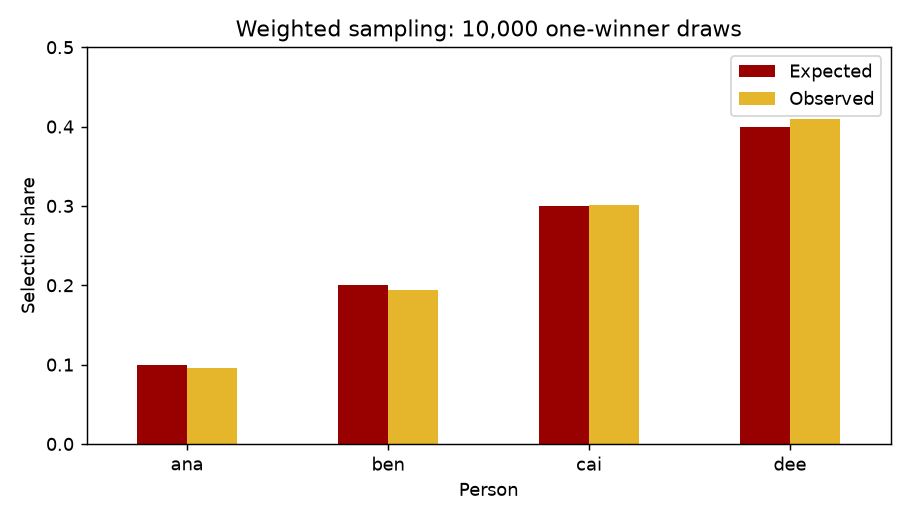

In [19]:
import matplotlib.pyplot as plt

runs = 10000
draws = weighted_team.sample(n=runs, weights="weight", replace=True,
                             random_state=576)
observed = draws["name"].value_counts(normalize=True)

comparison = weighted_team.set_index("name")[["weight"]].copy()
comparison["Expected"] = comparison["weight"] / comparison["weight"].sum()
comparison["Observed"] = observed.reindex(comparison.index, fill_value=0)
print(comparison[["Expected", "Observed"]])

ax = comparison[["Expected", "Observed"]].plot.bar(
    figsize=(7, 4), color=["#990000", "#e5b52b"], rot=0
)
ax.set(title=f"Weighted sampling: {runs:,} one-winner draws",
       xlabel="Person", ylabel="Selection share", ylim=(0, 0.5))
plt.tight_layout()
plt.show()


**Compare:** Are the observed bars close to the expected bars? Why might they differ? What changes when you reduce the number of draws?

**Important:** `weight / total weight` gives the chance in a one-winner draw. For several distinct winners (`n=slots, replace=False`), a person's chance of being included is generally different. With two people and two slots, both must be selected regardless of their positive weights.


### Weighted warm-up answer
The expected shares are 0.10, 0.20, 0.30, and 0.40. The observed shares should be near these values, with Dee selected most often in a large sample. Small differences are sampling variation. A fixed seed reproduces the experiment; it does not make its estimates exact.


**Compare:** How close is the estimate to your hand prediction? Why needn't it match exactly?

**My comparison:**

### Connect this to the weighted lottery
In the warm-up, each row is a different person. In the weighted lottery, each row is a **ticket**, so several rows can belong to the same person. Sampling tickets without replacement does not prevent selecting the same person twice.

Use the pattern `shuffle all tickets → keep each person's first appearance → take the first slots people`. In pandas, those operations are `sample(frac=1, random_state=seed)`, `drop_duplicates("person")`, and `head(slots)`. Count selections over many runs as in the warm-up. The solution below uses a shorter equivalent: one row per person, with ticket counts supplied through `weights="tickets"` and `replace=False`.

Now return to the app's formula and write your correction below.


### Warm-up answers
Ana's exact chance is 2/4 = 0.5: every person is equally likely to occupy either of the two selected positions. The simulation should give a value near 0.5, with some sampling variation.

The same seed and input reproduce the same draw. Different seeds can still produce the same pair. Reusing seed 1 inside every iteration would repeat one pair 1,000 times, producing a fraction of either 0 or 1 rather than a useful simulation.

Ticket rows are distinct entries, but selection is counted by person. Remove repeated people after shuffling, not before; otherwise the ticket weights lose their effect.


### Worked hand cases
One slot: A = **0.2**, B = **0.8**. Two slots: **both are 1**. The formula gives 0.4 and 1.6 for two slots.

The formula gives expected win counts for independent ticket draws with replacement, not selection probabilities for our lottery. Clipping at 1 still leaves A at an incorrect 0.4.

### A simpler correction: weighted pandas sampling
Use **one row per person**. `weights="tickets"` makes selection proportional to ticket counts; `replace=False` prevents selecting a person twice. After selecting a person, the remaining people compete using their relative weights. This gives the same selection probabilities as shuffling tickets and keeping each person's first appearance.

The next cell runs **one lottery**, not a probability calculation. This example uses the repository's pinned pandas 2.2.3 environment (`uv sync --frozen`).


In [20]:
people = pd.DataFrame({"person": ["A", "B"], "tickets": [1, 4]})
slots = 2
winners = people.sample(n=slots, weights="tickets", replace=False, random_state=576)
print(winners.to_string(index=False))


person  tickets
     B        4
     A        1


### Repeat the draw to estimate probabilities
Count how many runs select each person, then divide by the number of runs. `wins.loc[...] += 1` adds one win for each selected row.

Change the seed on each run: using the same fixed seed every time would repeat the same draw. The whole experiment remains reproducible. Inputs here are positive ticket counts, a positive number of runs, and slots between zero and the number of people.


In [21]:
def simulate_chances(weights, slots, runs=5000, seed=576):
    people = pd.DataFrame({"tickets": weights})  # one row per person
    wins = pd.Series(0, index=people.index)
    for run in range(runs):
        winners = people.sample(n=slots, weights="tickets", replace=False,
                                random_state=seed + run)
        wins.loc[winners.index] += 1
    return (wins / runs).tolist()

print("Simulation, one slot:", simulate_chances([1, 4], 1))
print("Simulation, two slots:", simulate_chances([1, 4], 2))


Simulation, one slot: [0.2098, 0.7902]
Simulation, two slots: [1.0, 1.0]


### Verify the correction and its limits
Check zero slots, enough slots for everyone, and three equally weighted people competing for one slot. Probabilities should be in [0, 1], and their sum should equal the number of slots because each run selects exactly that many distinct people.

Agreement with hand cases supports the simulation. It does not prove the process matches a real-world policy.

In [22]:
assert simulate_chances([1, 4], 0) == [0, 0]
assert simulate_chances([1, 4], 2) == [1, 1]
equal = simulate_chances([1, 1, 1], 1)
print("Equal weights, one slot:", equal)
assert all(0 <= chance <= 1 for chance in equal)
assert abs(sum(equal) - 1) < 1e-12
print("Hand-case and structural checks passed.")

Equal weights, one slot: [0.345, 0.3234, 0.3316]
Hand-case and structural checks passed.


## Apply the audit
Choose one number in your team's app:
1. What exactly should it measure?
2. What tiny case would help you check it?
3. Which assumption or line deserves inspection?
4. What evidence would justify a change?
